# Super cool experiment

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopandas import GeoDataFrame
from shapely import Polygon
from spatialdata.models import ShapesModel
from spatialdata.transformations import Identity
import numpy as np

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Import packages

In [2]:
path = "/media/sergio/ADAMEYKO_R5/xenium_datasets/Xenium_Prime_Mouse_Brain_Coronal_FF_outs"
sdata = spatialdata_io.xenium(path)

INFO     reading                                                                                                   
         /media/sergio/ADAMEYKO_R5/xenium_datasets/Xenium_Prime_Mouse_Brain_Coronal_FF_outs/cell_feature_matrix.h5 


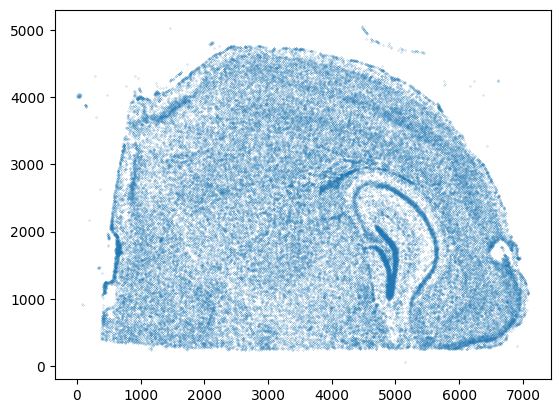

In [9]:
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.02)

In [ ]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[ 20150,2600,],
    max_coordinate=[ 28199.,13899.9,],
    target_coordinate_system="global")
cropped_sdata

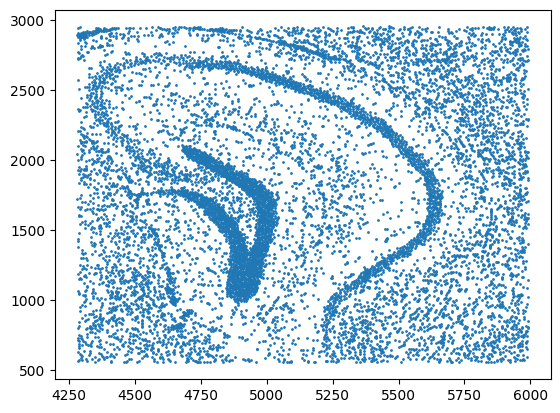

In [34]:
spat=[g[0] for g in cropped_sdata['table'].obsm['spatial']]
spat2=[g[1] for g in cropped_sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [48]:
del cropped_sdata['nucleus_labels']

In [49]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr"
cropped_sdata.write(outpath,overwrite=True)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr                                


# Read data

In [3]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo.zarr"
sdata=sd.read_zarr(outpath)

In [4]:
transcripts=sdata['transcripts'].compute()
transcripts.reset_index(drop=True,inplace=True)
sdata['transcripts']=sd.models.PointsModel.parse(transcripts)

### Process cell expressions

(11004, 5006)


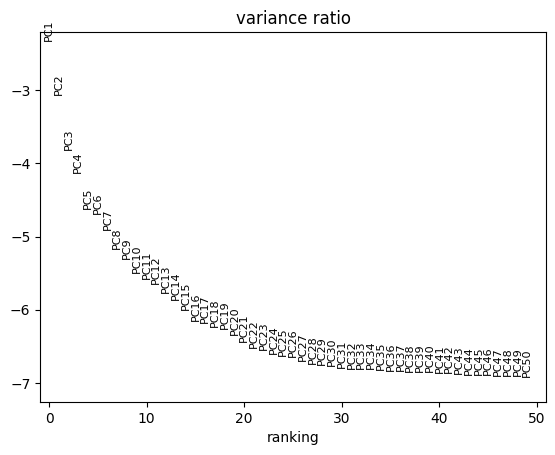

2025-03-27 07:58:19.104919: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-27 07:58:19.239894: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1743058699.299488 1450476 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1743058699.316699 1450476 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1743058699.429980 1450476 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

(11004, 4922)


In [5]:
adata = sdata["table"]
print(adata.shape)
adata.raw = adata.copy()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")

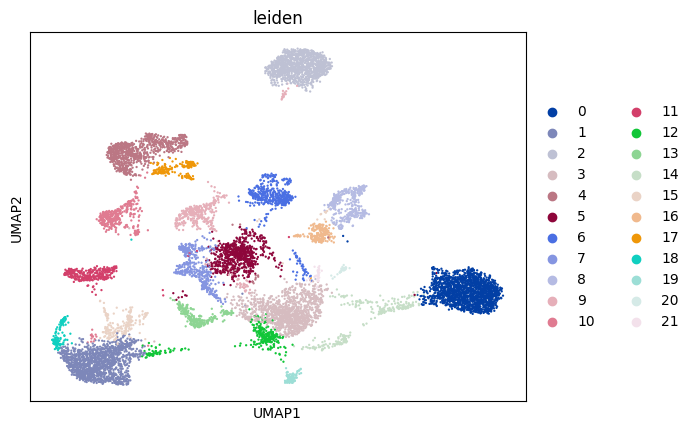

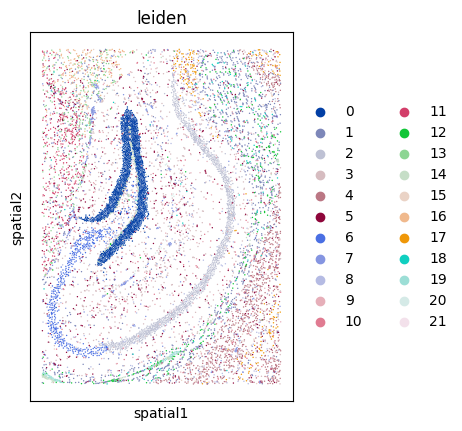

In [6]:
sc.pl.umap(adata,color='leiden')
sc.pl.spatial(adata,color='leiden',spot_size=10)

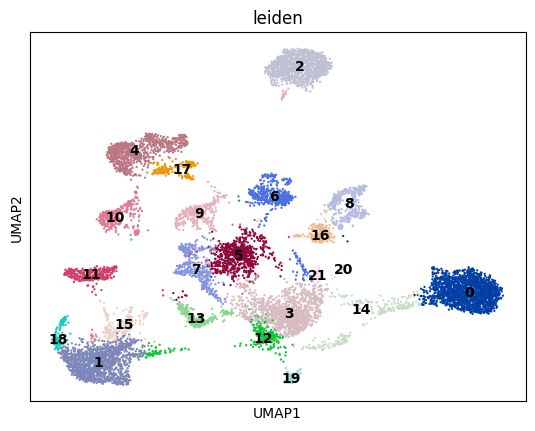

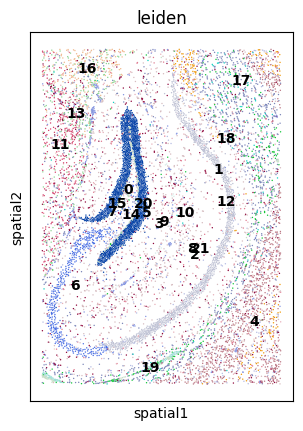

In [10]:
sc.pl.umap(adata,color='leiden',legend_loc='on data')
sc.pl.spatial(adata,color='leiden',spot_size=10,legend_loc='on data')

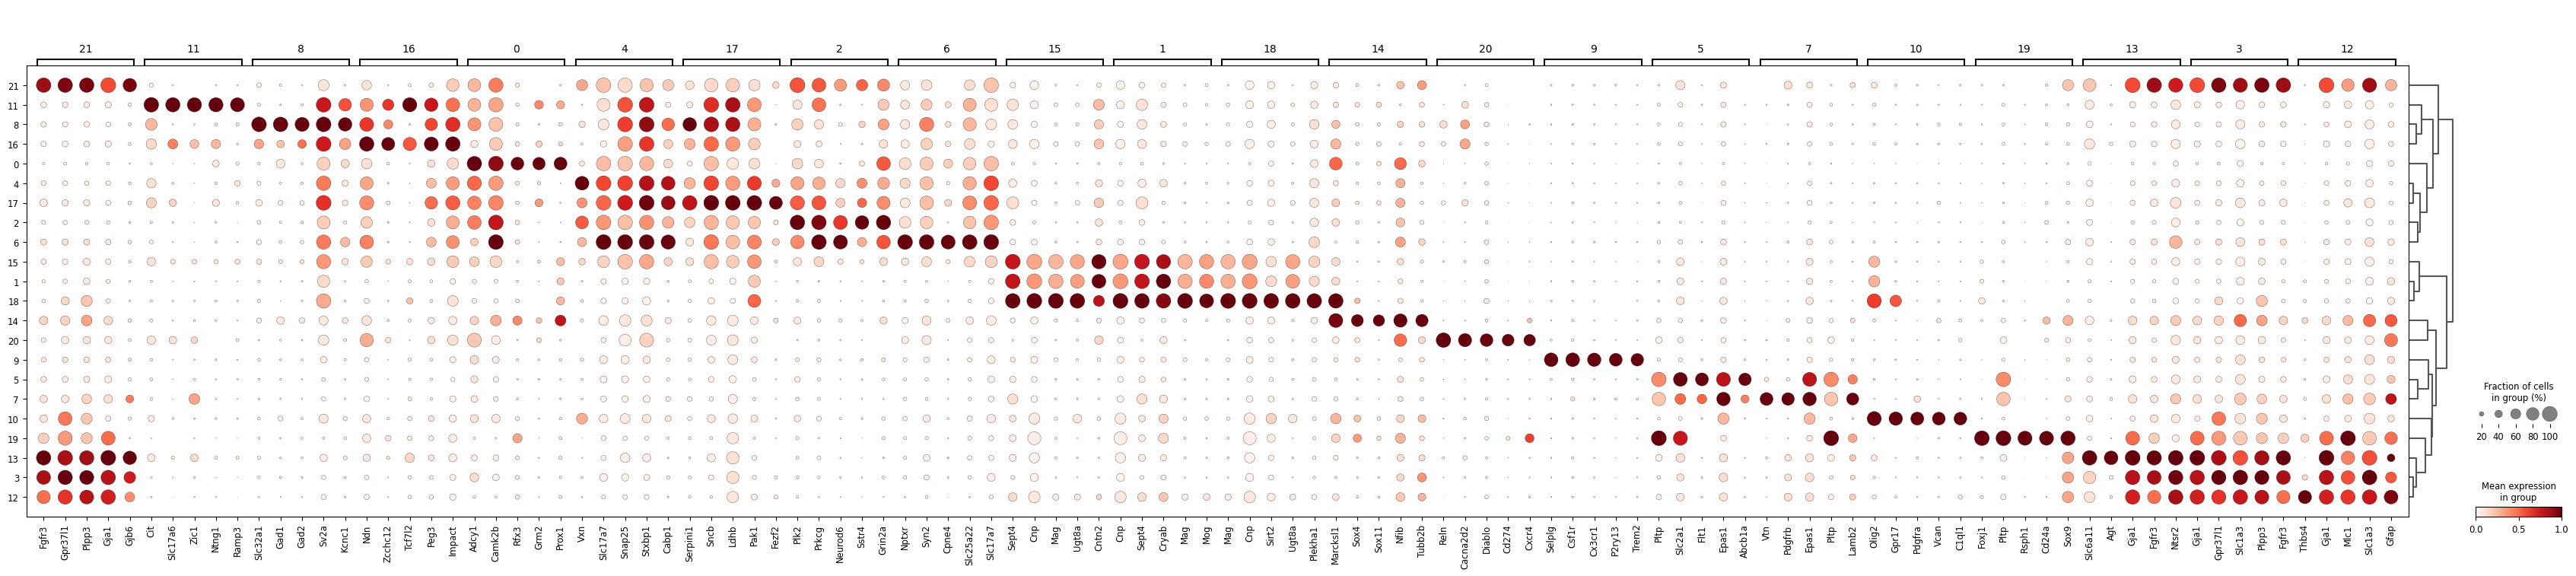

In [7]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=5)

In [12]:
ctdict={'0':'DG',
 '1':'Oligo','2':'CA1-2','3':'Astro','4':'Excitatory','5':'Endothelial','6':'CA3','7':'Pericyte','8':'Inhibitory','9':'Microglia',
 '10':'OPC','11':'Thal neuron','12':'Astro','13':'Astro','14':'Neuroblast','15':'Oligo',
 '16':'Habenula neurons','17':'Excitatory','18':'Oligo','19':'Ependymal','20':'CR neurons','21':'Astro'}

In [16]:
sdata['table'].obs['cell_type']=sdata['table'].obs['leiden'].map(ctdict)

In [31]:
import polars as pl
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from multiprocessing import Pool
from functools import partial

def process_dataframe(df: pl.DataFrame, binsize: float = None, n_threads: int = 4):
    """
    Process a Polars DataFrame by binning spatial coordinates, converting genes to categorical,
    and constructing sparse matrices for each gene.
    
    Args:
        df (pl.DataFrame): Input data containing "x", "y", "gene", "count".
        binsize (float, optional): Binning size for spatial coordinates.
        n_threads (int): Number of threads for parallel processing.
    
    Returns:
        dict: Dictionary of sparse matrices for each gene.
        tuple: Shape of the spatial grid.
        pl.DataFrame: DataFrame with bin assignments.
    """
    
    # Apply binning if provided
    if binsize:
        df = df.with_columns(
            (df["x"] / binsize).floor().alias("bin_x"),
            (df["y"] / binsize).floor().alias("bin_y")
        )
    else:
        df = df.with_columns(
            df["x"].alias("bin_x"),
            df["y"].alias("bin_y")
        )
    
    # Convert to integer type and shift coordinates to start at 0
    df = df.with_columns(
        (df["bin_x"] - df["bin_x"].min()).cast(pl.Int32).alias("bin_x"),
        (df["bin_y"] - df["bin_y"].min()).cast(pl.Int32).alias("bin_y")
    )
    
    # Ensure "count" column exists, otherwise fill with ones
    if "count" not in df.columns:
        df = df.with_columns(pl.lit(1, dtype=pl.UInt32).alias("count"))
    else:
        df = df.with_columns(df["count"].cast(pl.UInt32))
    
    # Ensure "gene" is categorical
    df = df.with_columns(df["gene"].cast(pl.Categorical))

    # Compute the shape of the spatial grid
    shape = (df["bin_x"].max() + 1, df["bin_y"].max() + 1)

    # Partition DataFrame by gene for parallel processing
    gene_groups = df.partition_by("gene", maintain_order=False)

    # Use partial to pass the shape argument
    process_gene_partial = partial(process_gene, shape=shape)

    with Pool(n_threads) as pool:
        results = dict(pool.map(process_gene_partial, gene_groups))

    return results, shape, df

def process_gene(group, shape):
    """Convert a gene DataFrame into a sparse matrix."""
    gene_name = group["gene"][0]
    x = group["bin_x"].to_numpy()
    y = group["bin_y"].to_numpy()
    counts = group["count"].to_numpy()
        
    # Convert to CSR sparse matrix
    sparse_matrix = coo_matrix((counts, (x, y)), shape=shape).tocsr()
        
    return gene_name, sparse_matrix

def integrated_sainsc_processing(
    sdata,
    binsize=3,
    celltype_key='leiden',
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    return_sainsc=False,
    copy=False,
    compressed_transcript_csv_path="compressed_transcript.csv.gz"
):
    """
    Process an sdata object by running an integrated sainsc analysis pipeline.
    
    This function extracts transcript information from sdata, prepares the data,
    bins it using sainsc tools (including a KDE and cell type assignment), and then
    maps cosine similarity and cell type assignment results back to the original sdata.
    
    Parameters
    ----------
    sdata : spatialdata object
        An object containing spatial points (with a key "transcripts") and a table
        of expression data. The object is expected to have attributes such as `points`
        and support a ["table"] lookup.
    binsize : int, optional (default=3)
        Bin size parameter to be used in the sainsc processing.
    celltype_key : str, optional (default='leiden')
        Key in sdata table metadata to use for grouping cell types.
    background_filter : float, optional (default=0.4)
        Threshold used for background filtering in the KDE calculation.
    gaussian_kernel_key : float, optional (default=2.5)
        Parameter controlling the gaussian kernel smoothing (unit: µm).
    n_threads : int, optional (default=16)
        Number of threads to use for processing.
    return_sainsc : bool, optional (default=False)
        If True, the function returns a tuple of (sdata, sainsc_output) where
        sainsc_output is a dictionary containing intermediate outputs.
    copy : bool, optional (default=True)
        If True, the function works on a copy of sdata and returns it.
        Otherwise, sdata is modified in place and None is returned (aside from sainsc_output).
    compressed_transcript_csv_path : str, optional (default="compressed_transcript.csv.gz")
        File path to store the temporary CSV of transcript data (gzip compressed).
    
    Returns
    -------
    sdata or (sdata, sainsc_output) : spatialdata object or tuple
        The modified sdata object (with updated transcript points) is returned.
        If return_sainsc is True, a tuple (modified sdata, sainsc_output) is returned,
        where sainsc_output is a dict containing:
            - "brain": the LazyKDE object with KDE and cell type assignment results,
            - "transcript2bin_info": a pandas DataFrame with binned transcript information,
            - "output_df": a DataFrame summarizing binned cell type and cosine similarity,
            - "threshold": the cosine similarity threshold computed from the data.
    """
    import numpy as np
    import pandas as pd
    import polars as pl
    from tqdm import tqdm
    import spatialdata as sd
    from sainsc import LazyKDE, GridCounts # , process_dataframe  # process_dataframe is assumed to be available


    # -------------------------------------------------------------------------
    # 1. Load and prepare transcript data from sdata.points
    # -------------------------------------------------------------------------
    # Extract relevant columns and compute the Dask/polars DataFrame
    transcripts_all = (
        sdata.points["transcripts"]
        [["feature_name", "x", "y", "codeword_category", "overlaps_nucleus", "transcript_id",'overlaps_cell']]
        .compute()
        .reset_index(drop=True)
    )
    # Rename for clarity and filter by desired gene type
    transcripts_all = transcripts_all.rename(columns={"feature_name": "gene"})
    transcripts_all = transcripts_all[transcripts_all["codeword_category"] == "predesigned_gene"]
    # Remove rows where the gene is not valid (e.g. string "nan")
    transcripts_all = transcripts_all[transcripts_all["gene"].astype(str) != "nan"]
    
    # Create a smaller DataFrame for CSV export
    transcripts = transcripts_all[["gene", "x", "y", "codeword_category"]].copy()
    transcripts.columns = ["gene", "x", "y", "codeword_category"]
    
    # Save to a compressed CSV file (temporary file)
    transcripts.to_csv(compressed_transcript_csv_path, compression="gzip", index=False)
    
    # Read the CSV using Polars for fast processing
    transcripts = pl.read_csv(
        compressed_transcript_csv_path,
        columns=["gene", "x", "y"],
        schema_overrides={"gene": pl.Categorical},
        n_threads=n_threads,
    )
    
    # -------------------------------------------------------------------------
    # 2. Create a brain object using LazyKDE and process transcript data
    # -------------------------------------------------------------------------
    brain = LazyKDE.from_dataframe(transcripts, resolution=1000, binsize=binsize, n_threads=n_threads)
    
    # Process the transcripts into binned data
    results, shape, transcript2bin_info = process_dataframe(transcripts, binsize=binsize, n_threads=n_threads)
    transcript2bin_info = transcript2bin_info.to_pandas()  # Convert to pandas for easier manipulation
    transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)
    
    # -------------------------------------------------------------------------
    # 3. Align coordinates and map overlap information
    # -------------------------------------------------------------------------
    # Round x and y coordinates to 4 decimal places for consistency
    transcripts_all["x"] = transcripts_all["x"].round(4)
    transcripts_all["y"] = transcripts_all["y"].round(4)
    transcripts_all["xy"] = transcripts_all["x"].astype(str) + "_" + transcripts_all["y"].astype(str)
    
    transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)
    
    # Map overlap information (from nucleus and cell) from transcripts_all to transcript2bin_info
    id2overlap = dict(zip(transcripts_all["xy"], transcripts_all["overlaps_nucleus"]))
    id2overlap_cell = dict(zip(transcripts_all["xy"], transcripts_all["overlaps_cell"]))
    transcript2bin_info["overlaps_nucleus"] = transcript2bin_info["xy"].map(id2overlap)
    transcript2bin_info["overlaps_cell"] = transcript2bin_info["xy"].map(id2overlap_cell)
    
    # -------------------------------------------------------------------------
    # 4. Run KDE, background filtering and cell type assignment
    # -------------------------------------------------------------------------
    brain.calculate_total_mRNA()
    brain.gaussian_kernel(gaussian_kernel_key, unit="um")
    brain.calculate_total_mRNA_KDE()
    brain.filter_background(background_filter)
    
    # Retrieve expression data from sdata table and compute cell type signatures
    adata = sdata["table"]
    expr = adata.to_df()
    expr["cell type"] = adata.obs[celltype_key]
    signatures = expr.groupby("cell type").mean().transpose()
    
    # Assign cell types to the brain (KDE) object
    brain.assign_celltype(signatures, log=True)
    
    # -------------------------------------------------------------------------
    # 5. Map binned features (cell type, assignment score, cosine similarity)
    # -------------------------------------------------------------------------
    # Flatten the binned cell type map, assignment scores, and cosine similarity matrix
    celltype_flat = brain.celltype_map.flatten()
    assignment_score_flat = brain.assignment_score.flatten()
    cosine_similarity_flat = brain.cosine_similarity.flatten()
    
    # Get the bin grid coordinates based on the shape of the cell type map
    n_rows, n_cols = brain.celltype_map.shape
    x_coordinates, y_coordinates = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
    x_coordinates = x_coordinates.flatten()
    y_coordinates = y_coordinates.flatten()
    
    # Create a DataFrame summarizing the binned data
    output_df = pd.DataFrame({
        "bin_x": x_coordinates,
        "bin_y": y_coordinates,
        "cell type": celltype_flat,
        "assignment_score": assignment_score_flat,
        "cosine_similarity": cosine_similarity_flat
    })
    # Map cell type indices to actual names using the brain's celltypes list
    num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes))
    output_df["cell type"] = output_df["cell type"].map(num2ct)
    output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)
    
    # Build mapping dictionaries from binned information
    bin2celltype = dict(zip(output_df["bin_x_y_id"], output_df["cell type"]))
    bin2cosine_similarity = dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"]))
    
    # Map the bin-level assignments to the transcript-level information
    transcript2bin_info["closest_cell_type"] = transcript2bin_info["bin_x_y_id"].map(bin2celltype)
    transcript2bin_info["cosine_similarity"] = transcript2bin_info["bin_x_y_id"].map(bin2cosine_similarity)
    
    # Compute a threshold based on the 10th percentile of cosine similarity for transcripts overlapping cells
    threshold = np.percentile(transcript2bin_info.loc[transcript2bin_info["overlaps_cell"] == 1, "cosine_similarity"], 10)
    transcript2bin_info["match_cell_signature"] = transcript2bin_info["cosine_similarity"] > threshold
    
    # -------------------------------------------------------------------------
    # 6. Map back the cosine similarity and cell type to the original transcripts
    # -------------------------------------------------------------------------
    xy2cosine_similarity = dict(zip(transcript2bin_info["xy"], transcript2bin_info["cosine_similarity"]))
    xy2closest_cell_type = dict(zip(transcript2bin_info["xy"], transcript2bin_info["closest_cell_type"]))
    
    transcripts_all["cosine_similarity"] = transcripts_all["xy"].map(xy2cosine_similarity)
    transcripts_all["closest_cell_type"] = transcripts_all["xy"].map(xy2closest_cell_type)
    
    # Build dictionaries to map by original transcript index
    id2cosine = dict(zip(transcripts_all.index, transcripts_all["cosine_similarity"]))
    id2ct = dict(zip(transcripts_all.index, transcripts_all["closest_cell_type"]))
    
    # Retrieve the original transcripts data from sdata and update with new features
    transi = sdata.points["transcripts"].compute()
    transi["cosine_similarity"] = transi.index.map(id2cosine)
    transi["closest_cell_type"] = transi.index.map(id2ct)
    transi["match_cell_signature"] = transi["cosine_similarity"] > threshold
    
    # Reformat the updated transcripts DataFrame into a spatialdata Points model
    sdata.points["transcripts"] = sd.models.PointsModel.parse(transi)
    
    # Prepare optional sainsc output for further inspection
    sainsc_output = {
        "brain": brain,
        "transcript2bin_info": transcript2bin_info,
        "output_df": output_df,
        "threshold": threshold
    }
    
    if return_sainsc:
        return sdata, sainsc_output
    else:
        return sdata


In [35]:
transcripts['feature_name'].isin(sdata['table'].var.index)

0           True
1           True
2           True
3           True
4           True
            ... 
28324847    True
28324848    True
28324849    True
28324850    True
28324851    True
Name: feature_name, Length: 28324852, dtype: bool

In [29]:
trans=sdata['transcripts'].compute()
trans['overlaps_cell']=trans['cell_id']!='UNASSIGNED'
sdata.points["transcripts"] = sd.models.PointsModel.parse(trans)

In [40]:
count=pd.crosstab(trans['feature_name'],trans['overlaps_cell'])

In [ ]:
sdata=integrated_sainsc_processing(sdata,binsize=3,celltype_key='cell_type',background_filter=0.4,
    gaussian_kernel_key=2.5,n_threads=16,return_sainsc=False,copy=True,compressed_transcript_csv_path="compressed_transcript.csv.gz")

ValueError: Not all genes in the gene signature are part of this KDE.

# Define extracellular proportion

In [50]:
troutpy.pp.define_extracellular(sdata,layer='transcripts',method='cells')

## Quantify exRNa

In [60]:
troutpy.tl.extracellular_enrichment(sdata)

In [ ]:

gen=np.unique(sdata['transcripts']['feature_name'].compute().astype(str))
control_codewords = [g for g in gen if 'Con' in g ]

troutpy.tl.quantify_overexpression(
    sdata,layer="transcripts",codeword_key="feature_name",
    control_codewords=control_codewords,gene_key="feature_name",
    percentile_threshold=99.99)

Added 'xrna_metadata' table with 13074 unique genes to the SpatialData object.


False


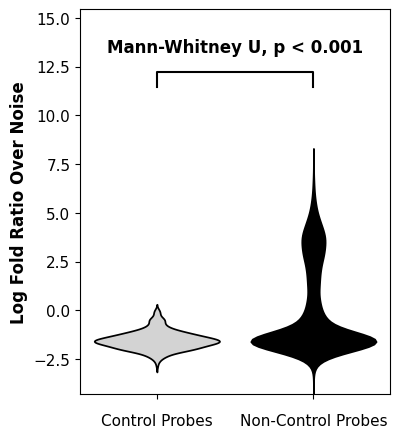

In [58]:
troutpy.pl.logfoldratio_over_noise(sdata,test_method="auto")

In [59]:
import pandas as pd
pd.crosstab(sdata['xrna_metadata'].var['p_value_Poisson']<0.0005,sdata['xrna_metadata'].var['control_probe'])

control_probe,False,True
p_value_Poisson,,
False,14,0
True,12464,595


# Test diffussion

In [24]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=3)

In [63]:
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
from sklearn.neighbors import KDTree
from spatialdata import SpatialData
from tqdm import tqdm

def compute_source_score(
    sdata: SpatialData,
    layer: str = "transcripts",
    gene_key: str = "feature_name",
    coord_keys: list = None,  # type: ignore
    lambda_decay: float = 0.1,
    copy: bool = False,
    celltype_key: str = "cell type",
):
    """
    Computes the probabilities of each extracellular transcript originating from a specific cell.

    Parameters
    ----------
    sdata
        The input spatial data object.
    layer
        The layer in `sdata.points` containing the transcript data. Default is 'transcripts'.
    gene_key
        Column name in the transcript data representing gene identifiers. Default is 'feature_name'.
    xcoord, ycoord
        Column names for spatial coordinates of transcripts and cell centroids.
    lambda_decay
        The exponential decay factor for distances.
    copy
        If True, returns a modified copy of the SpatialData object.
    celltype_key
        Key for cell type annotations in the cell table.

    Returns
    -------
    sdata
        Updated SpatialData object with source scores added in sdata.tables['source_score'], including distance to closest cell
    """
    if coord_keys is None:
        coord_keys = ["x", "y"]
    xcoord = coord_keys[0]
    ycoord = coord_keys[1]

    transcripts = sdata.points[layer].compute()
    cells = sdata["table"].to_df()
    coord_cells = sdata["table"].obsm["spatial"]
    cell_types = sdata["table"].obs[celltype_key]
    all_cell_types = cell_types.unique()

    # Ensure necessary columns exist
    required_cols = [xcoord, ycoord, gene_key]
    for col in required_cols:
        if col not in transcripts.columns and col not in cells.columns:
            raise ValueError(f"Required column '{col}' is missing.")

    # Filter for extracellular transcripts only
    extracellular_transcripts = transcripts[transcripts["extracellular"]]
    probabilities_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=all_cell_types, dtype=float)

    # Precompute KDTree for all cell coordinates
    closet_cell_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=["closest_cell", "closest_celltype", "distance"])

    # Process each gene
    for gene in tqdm(cells.columns.unique(), desc="Processing genes"):
        # Filter transcripts and cells for the current gene
        gene_transcripts = extracellular_transcripts[extracellular_transcripts[gene_key] == gene]

        gene_mask = cells[gene] > 0  # Mask for cells expressing the gene
        if not gene_mask.any() or gene_transcripts.empty:
            continue
        transcript_coords = gene_transcripts[[xcoord, ycoord]].to_numpy()
        gene_cells = cells.loc[gene_mask]
        coord_cells_filt = coord_cells[gene_mask]
        cell_types_filt = cell_types[gene_mask]

        # Compute distances between transcripts and filtered cells
        kdtree = KDTree(coord_cells_filt)
        distances, cell_indices = kdtree.query(transcript_coords, k=len(coord_cells_filt))

        # compute_min_dist
        distances_min = np.min(distances, axis=1)
        distances_idx = cell_indices[:, 0]
        cell_id_min = gene_cells.index[distances_idx]
        cell_type_min = cell_types_filt[distances_idx]

        # Get the gene-specific expression values
        cell_exprs = gene_cells[gene].to_numpy()

        # Compute exponential decay scores
        exp_decay = np.exp(-lambda_decay * distances)
        scores = exp_decay * cell_exprs[cell_indices]

        # Aggregate scores by cell type
        for i, transcript_idx in enumerate(gene_transcripts.index):
            cell_indices_i = cell_indices[i]
            scores_i = scores[i]
            types_i = cell_types_filt.iloc[cell_indices_i].to_numpy()

            # add min_distance
            closet_cell_table.loc[transcript_idx, "distance"] = distances_min[i]
            closet_cell_table.loc[transcript_idx, "closest_cell"] = cell_id_min[i]
            closet_cell_table.loc[transcript_idx, "closest_celltype"] = cell_type_min[i]
            for cell_type in all_cell_types:
                probabilities_table.loc[transcript_idx, cell_type] = scores_i[types_i == cell_type].sum()

    # We format all probabilieies as an anndata, stored in sdata.tables['source_score']
    prob_table = sc.AnnData(probabilities_table)
    prob_table.obs[gene_key] = list(extracellular_transcripts[gene_key])
    prob_table.obs["distance"] = list(closet_cell_table["distance"].astype(float))
    #prob_table.obs["feature_name"] = list(closet_cell_table["feature_name"].astype(str))
    prob_table.obs["closest_cell"] = list(closet_cell_table["closest_cell"].astype(str))
    prob_table.obs["closest_celltype"] = list(closet_cell_table["closest_celltype"].astype(str))

    prob_table.obsm["spatial"] = extracellular_transcripts[[xcoord, ycoord]].to_numpy()
    sdata.tables["source_score"] = prob_table
    return sdata.copy() if copy else None


In [64]:
from tqdm import tqdm
compute_source_score(sdata, layer="transcripts", gene_key="feature_name", lambda_decay=0.1, copy=False, celltype_key="cell_type")

Processing genes:   1%|          | 52/4922 [03:49<5:57:53,  4.41s/it] 


KeyboardInterrupt: 

In [ ]:
troutpy.tl.assess_diffussion( sdata, gene_key= "feature_name", distance_key= "distance")

In [ ]:
troutpy.tl.extracellular_enrichment(sdata)

In [65]:
troutpy.tl.spatial_variability(sdata, gene_key="feature_name", n_neighbors=10, square_size=20)

Extracting gene counts: 100%|██████████| 12531/12531 [00:03<00:00, 3960.25it/s]


In [66]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,square_size = 8)
troutpy.tl.in_out_correlation(sdata,n_neighbors=20)

In [78]:
tran.columns

Index(['x', 'y', 'z', 'feature_name', 'cell_id', 'overlaps_nucleus', 'is_gene',
       'qv', 'transcript_id', 'codeword_category', 'codeword_index',
       'fov_name', 'nucleus_distance', 'overlaps_cell', 'extracellular'],
      dtype='object')

In [81]:
tran=sdata['transcripts'].compute()
tran['extracellular']=tran['extracellular'].astype(bool)
#tran['control_probe']=tran['control_probe'].astype(bool)
sdata.points["transcripts"] = sd.models.PointsModel.parse(tran)

In [86]:
sdata['xrna_metadata'].var['control_probe']=sdata['xrna_metadata'].var['control_probe'].astype(bool)

In [90]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo_processed.zarr"
sdata.write(outpath,overwrite=True)

INFO     The Zarr backing store has been changed from                                                              
         media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo_processed.zarr the new file path:    
         /media/sergio/Meninges/troutpy/xenium_msbrain/xenium_msbrain_5k_hippo_processed.zarr                      


In [88]:
sdata['xrna_metadata'].var

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue
Hcfc1,10902.0,4.332761,False,0.000000e+00,0.581269,0.418731,-0.252712,0.074715,0.000000e+00,0.000018,0.000000e+00,0.037609,7.944066e-05
Snrpn,35483.0,5.512868,False,0.000000e+00,0.584900,0.415100,-0.237779,0.359265,0.000000e+00,0.000018,0.000000e+00,0.296408,5.169234e-222
Csde1,20409.0,4.959791,False,0.000000e+00,0.696996,0.303004,0.252336,0.107677,0.000000e+00,0.000018,0.000000e+00,0.003929,6.802235e-01
Adh5,10228.0,4.268944,False,0.000000e+00,0.682636,0.317364,0.185213,0.032458,1.454392e-14,0.000018,9.293722e-14,0.017980,5.929586e-02
Dlg4,74026.0,6.248231,False,0.000000e+00,0.317226,0.682774,-1.347247,0.512979,0.000000e+00,0.000018,0.000000e+00,0.174842,2.920296e-76
...,...,...,...,...,...,...,...,...,...,...,...,...,...
UnassignedCodeword_11805,15.0,-2.255890,False,2.200754e-10,0.866667,0.133333,1.291103,-0.000221,4.883604e-01,0.000018,5.000000e-01,NaN,NaN
UnassignedCodeword_16315,10.0,-2.661355,False,7.645993e-06,1.000000,0.000000,inf,NaN,NaN,NaN,NaN,NaN,NaN
NegControlCodeword_18919,12.0,-2.479034,True,1.469258e-07,1.000000,0.000000,inf,NaN,NaN,NaN,NaN,NaN,NaN
UnassignedCodeword_5184,16.0,-2.191352,False,2.204081e-11,0.750000,0.250000,0.517913,-0.000385,4.731501e-01,0.000018,5.000000e-01,NaN,NaN


## Exploration of results

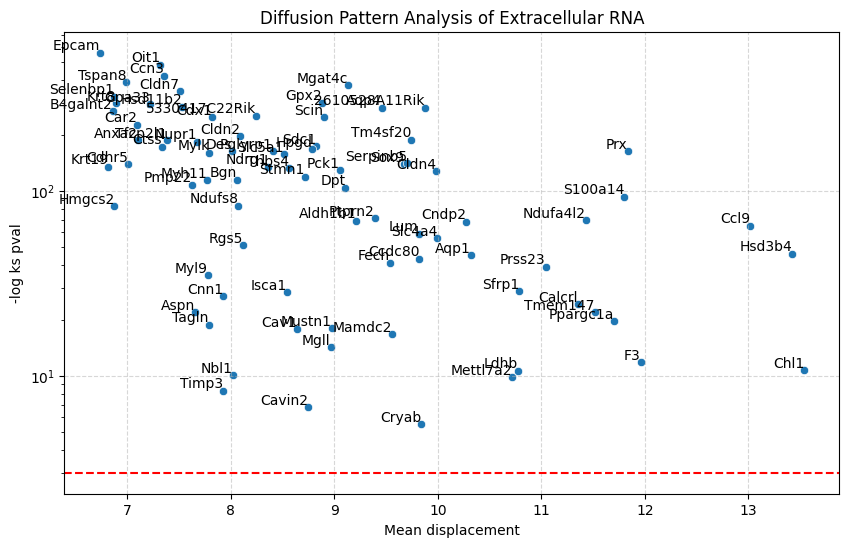

In [ ]:
# this we can't currently do
troutpy.pl.diffusion_results(sdata, y_col='-log_ks_pval',y_logscale=True)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


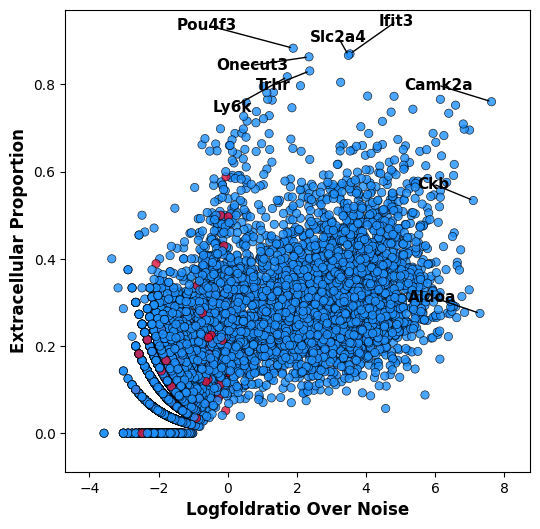

In [89]:
troutpy.pl.metric_scatter(sdata,
x_metric="logfoldratio_over_noise",
y_metric="extracellular_proportion",
label_top_n_x=3,label_top_n_y=6)

In [65]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False,n_bins=20)

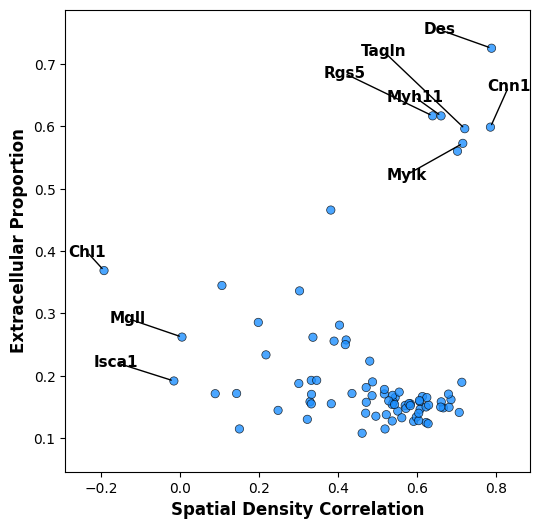

In [70]:
troutpy.pl.metric_scatter(sdata,
x_metric="spatial_density_correlation",
y_metric="extracellular_proportion",
label_top_n_x=0,label_top_n_y=6,label_bottom_n_x=3)

In [75]:
bottom_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation')['spatial_density_correlation'].keys()[0:6]
top_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=False)['spatial_density_correlation'].keys()[0:6]

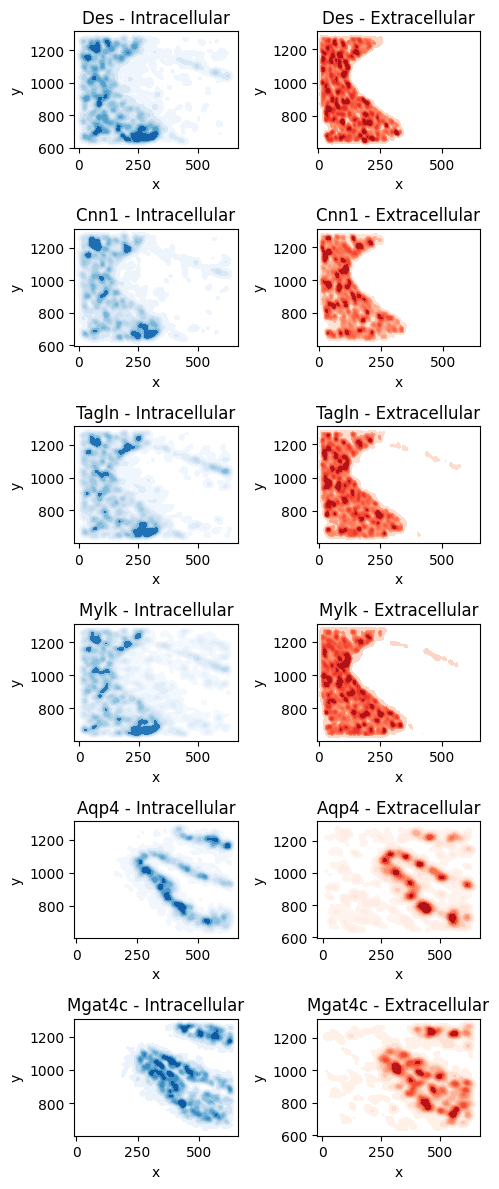

In [76]:
troutpy.pl.intra_extra_density(
    sdata, top_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,12)
)

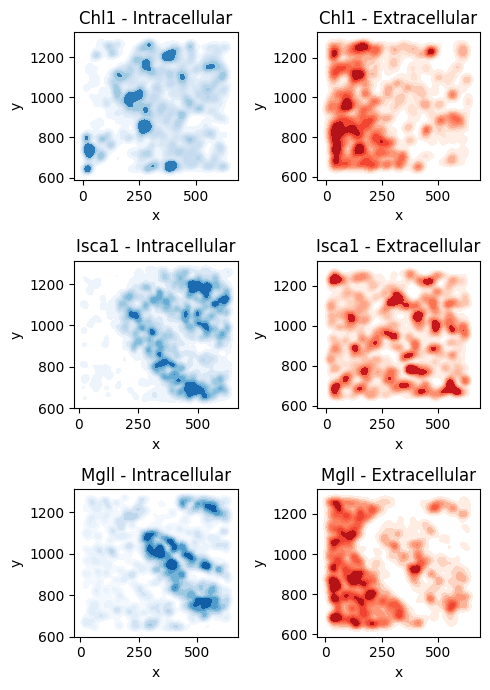

In [73]:
troutpy.pl.intra_extra_density(
    sdata, bottom_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,7)
)

In [77]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=3)

In [78]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False)

In [68]:
gen=sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Des,1718466,5.372709,0.0,0.420576,0.579424,-1.527242,0.794840,0.0,0.000002,0.0,0.559565,0.0,235.874054,0.898087,0.038660
Rgs5,1292465,5.087829,0.0,0.486830,0.513170,-1.259523,0.767295,0.0,0.000002,0.0,0.572803,0.0,114.919647,0.896741,0.045251
Myh11,2954152,5.914489,0.0,0.500571,0.499429,-1.204548,0.803042,0.0,0.000002,0.0,0.614265,0.0,175.079300,0.895307,0.043182
Cnn1,1095387,4.922385,0.0,0.514510,0.485490,-1.148774,0.752762,0.0,0.000002,0.0,0.605094,0.0,132.244095,0.919385,0.027027
Tagln,1883852,5.464596,0.0,0.519607,0.480393,-1.128365,0.776630,0.0,0.000002,0.0,0.617004,0.0,165.001114,0.906204,0.035734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pglyrp1,491612,4.121212,0.0,0.860886,0.139114,0.615838,0.403058,0.0,0.000002,0.0,0.478195,0.0,135.951080,0.964150,0.015897
5330417C22Rik,588109,4.300434,0.0,0.862925,0.137075,0.632968,0.400191,0.0,0.000002,0.0,0.506649,0.0,118.910728,0.962626,0.014965
Cldn4,175347,3.090289,0.0,0.863494,0.136506,0.637783,0.333075,0.0,0.000002,0.0,0.370564,0.0,71.764809,0.955798,0.016547
Ptprn2,200592,3.224795,0.0,0.870872,0.129128,0.701861,0.251532,0.0,0.000002,0.0,0.338198,0.0,142.429138,0.942986,0.017906


In [61]:
gen=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Mgll,435836,4.000788,0.0,0.758866,0.241134,-0.060361,0.489629,0.0,0.000002,0.0,0.340680,0.0,63.303387,0.636961,0.051766
Bgn,560456,4.252273,0.0,0.816630,0.183370,0.286846,0.344240,0.0,0.000002,0.0,0.300215,0.0,73.513901,0.767284,0.032882
Dpt,390914,3.892010,0.0,0.735840,0.264160,-0.182376,0.390313,0.0,0.000002,0.0,0.308351,0.0,163.018616,0.782256,0.039425
Chl1,215006,3.294188,0.0,0.652428,0.347572,-0.577102,0.388354,0.0,0.000002,0.0,0.201248,0.0,106.977654,0.782540,0.035466
Sfrp1,170556,3.062586,0.0,0.805794,0.194206,0.216077,0.255329,0.0,0.000002,0.0,0.253969,0.0,113.822319,0.791838,0.036108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oit1,1867761,5.456018,0.0,0.860657,0.139343,0.613923,0.492231,0.0,0.000002,0.0,0.667311,0.0,143.438889,0.969365,0.012514
Tfcp2l1,1468150,5.215280,0.0,0.830938,0.169062,0.385460,0.498740,0.0,0.000002,0.0,0.631032,0.0,71.777977,0.969914,0.010797
Cldn2,611131,4.338833,0.0,0.881705,0.118295,0.801840,0.429227,0.0,0.000002,0.0,0.580331,0.0,75.898804,0.972266,0.016874
Aqp4,177059,3.100005,0.0,0.809832,0.190168,0.242085,0.362197,0.0,0.000002,0.0,0.434927,0.0,17.113632,0.972980,0.019523


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f53b1ccc5b0>>
Traceback (most recent call last):
  File "/home/sergio/.local/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


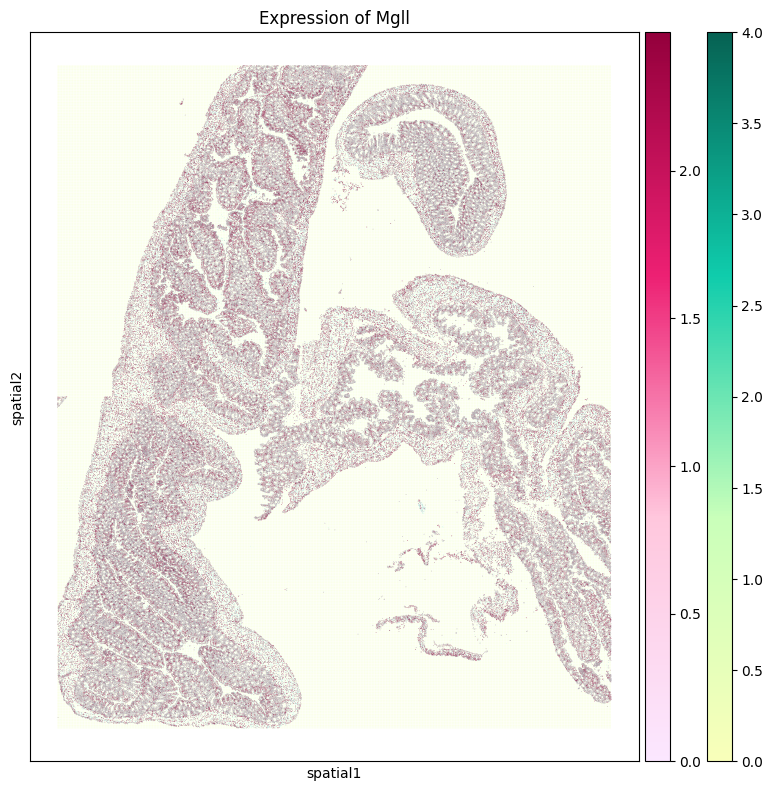

In [66]:
troutpy.pl.spatial_inout_expression(sdata,'Bgn',spot_size_cells=6,spot_size_extra=4)

## Signature analysis

In [ ]:
xenium_path_cropped = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata=sd.read_zarr(xenium_path_cropped)

In [100]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,square_size = 20)

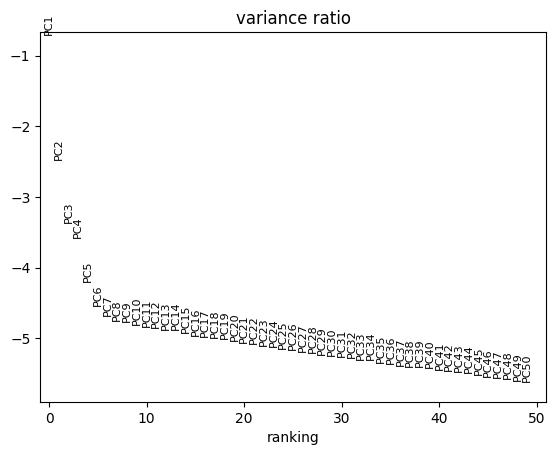

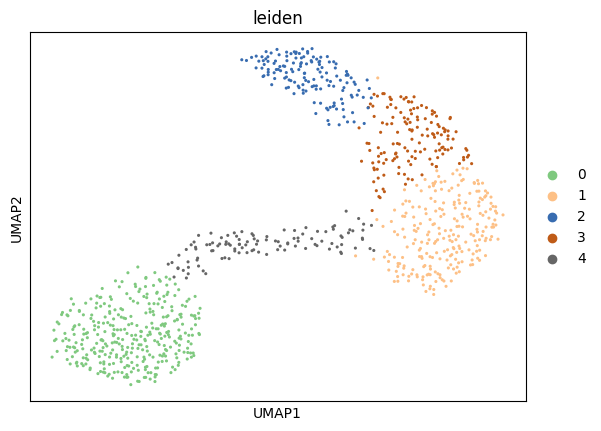

In [101]:
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_cells(adata, min_genes=4)
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=20)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
# neighbors
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.7)
sc.pl.umap(adata,color='leiden',palette='Accent',s=20)

In [102]:
adata

AnnData object with n_obs × n_vars = 984 × 81
    obs: 'instance_id', 'region', 'n_genes', 'n_counts', 'leiden'
    var: 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

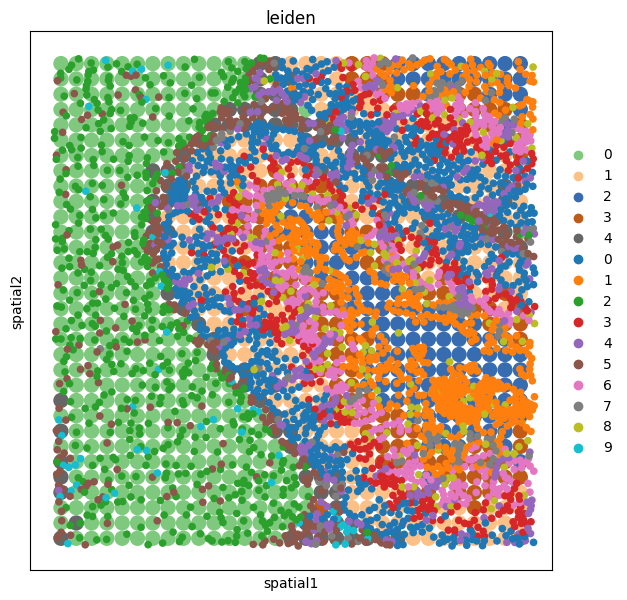

In [104]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=20,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=10,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

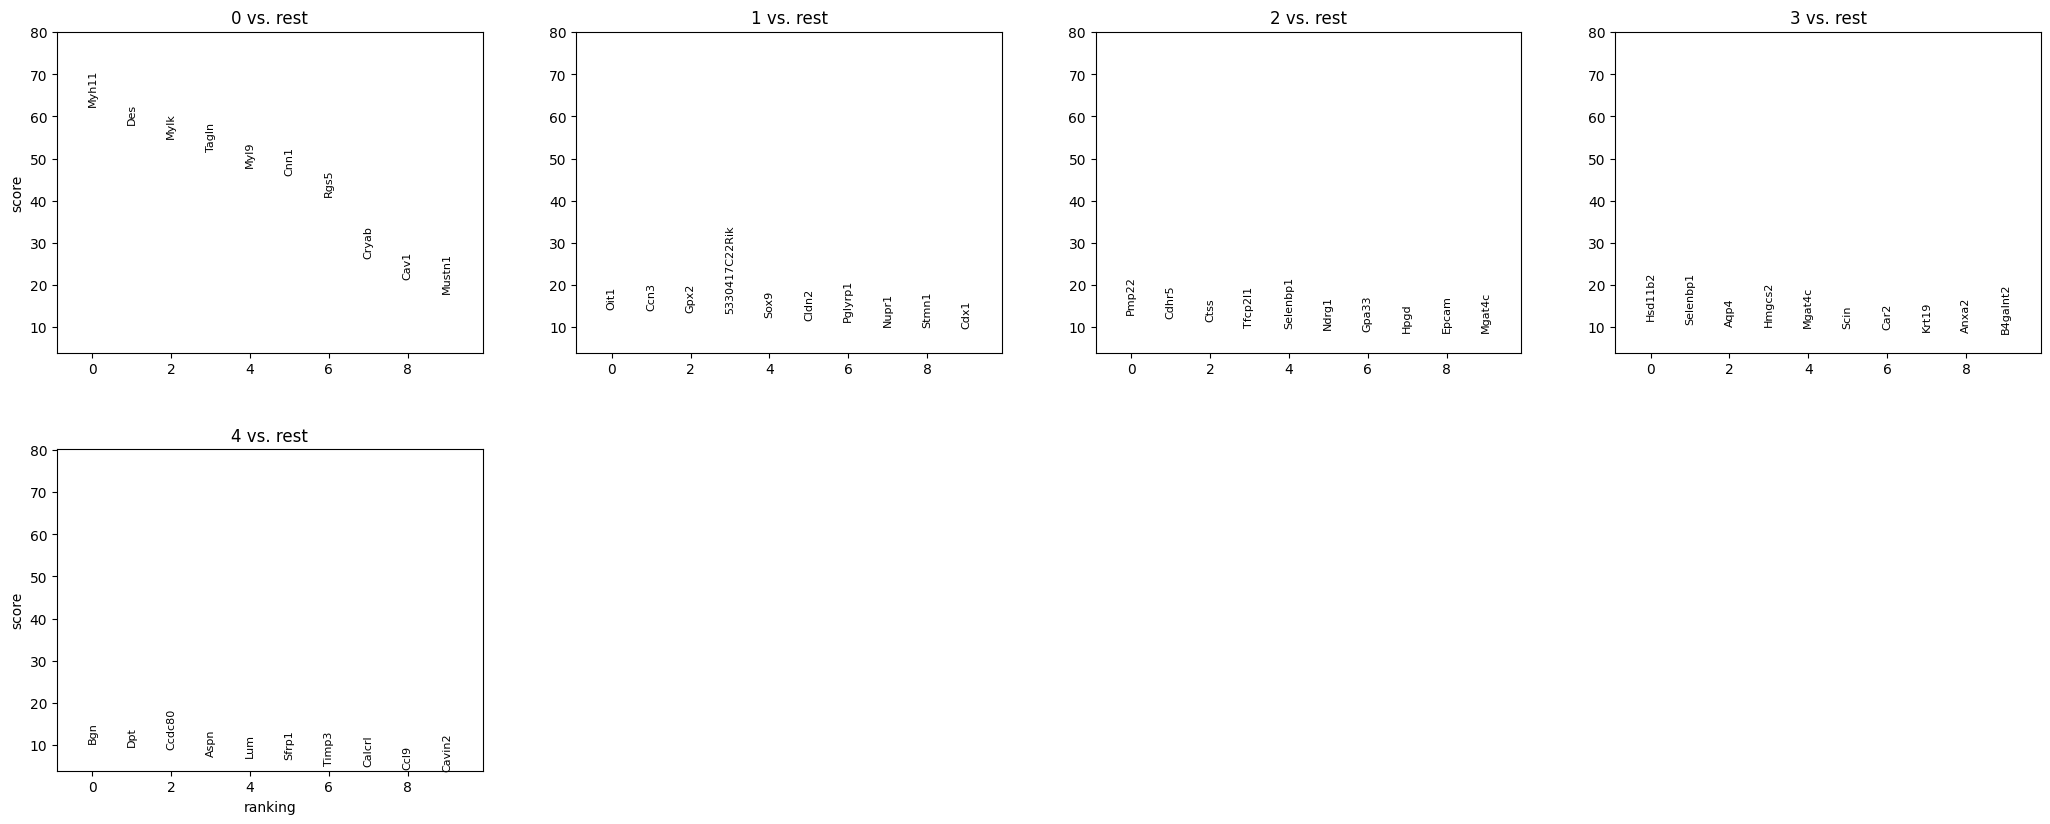

In [105]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups(adata,groupby='leiden',n_genes=10)

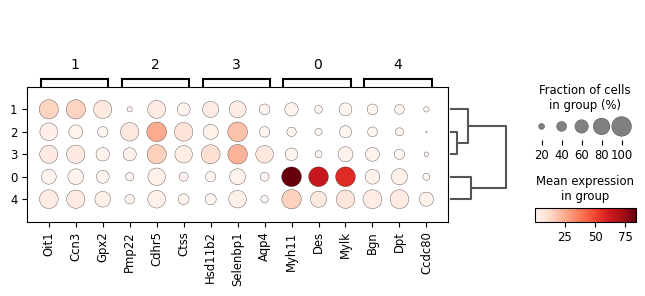

In [106]:
sc.pl.rank_genes_groups_dotplot(adata,groupby='leiden',n_genes=3)

In [107]:
troutpy.tl.latent_factor(sdata,method='NMF',layer='segmentation_free_table', n_components=10)

In [108]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer = "segmentation_free_table", cellular_layer='table')

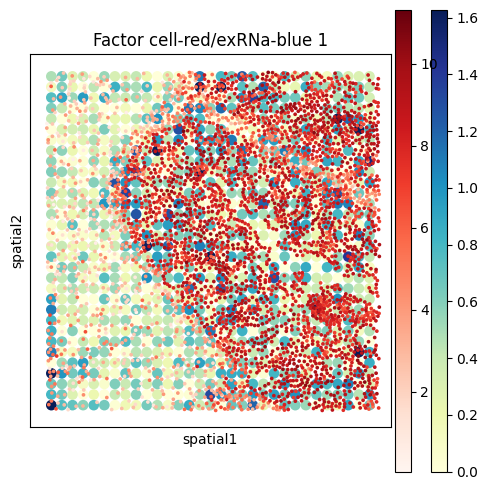

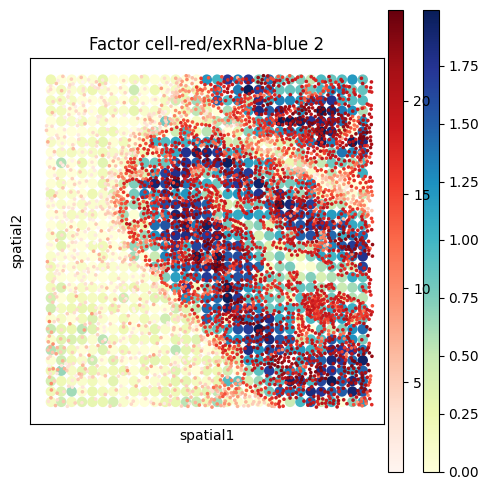

In [119]:
troutpy.pl.paired_nmf_factors(sdata,layer='segmentation_free_table',spot_size_exrna=20,spot_size_cells=7, figsize=(5, 5), n_factors=2)

[<Axes: title={'center': 'NNAT'}, xlabel='spatial1', ylabel='spatial2'>]

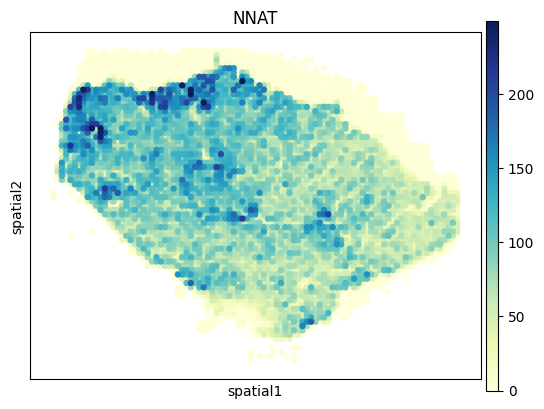

In [61]:
gene='NNAT'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

[<Axes: title={'center': 'MT-CO2'}, xlabel='spatial1', ylabel='spatial2'>]

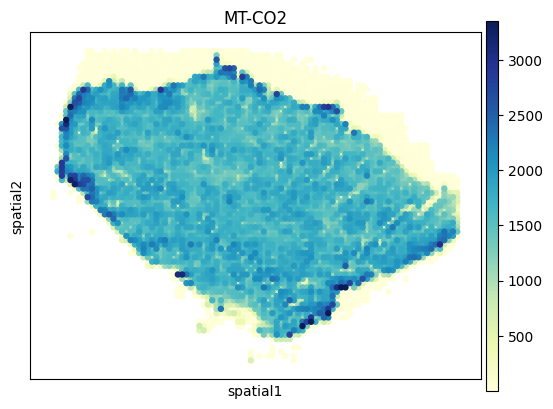

In [52]:
gene='MT-CO2'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

In [ ]:
sdata['xrna_metadata'].var.sort_values(by='moran_I',ascending=False).head(10)

In [35]:
troutpy.pl.nmf_gene_contributions(sdata, nmf_adata_key="segmentation_free_table", vmin=0.0, vmax=0.02, save=False, figsize=(4, 5))

KeyError: 'H_nmf'